<a href="https://colab.research.google.com/github/IpanTEKNIKINFORMATIKA/Latihan-Mobile/blob/main/Hands_On_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [66]:
df_mentah = pd.read_csv(
    "case2_customer_churn.csv.csv"
)

df = df_mentah.copy()

print("Ukuran dataset:", df.shape)

display(df.head())

Ukuran dataset: (5000, 12)


,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
0,TEL000001,41.0,Dua Tahun,140611.0,5860742.0,DSL,8.0,Tidak,11.0,331.0,Transfer Bank,Aktif
1,TEL000002,5.0,Tahunan,363720.0,1742224.0,Tidak Ada,7.0,Ya,12.0,156.0,Autodebet,Aktif
2,TEL000003,56.0,Bulanan,208727.0,11685438.0,DSL,6.0,Tidak,9.0,105.0,Transfer Bank,Churn
3,TEL000004,NaN,Dua Tahun,135607.0,5599065.0,Fiber Optik,2.0,Ya,12.0,100.0,Kartu Kredit,Churn
4,TEL000005,7.0,Bulanan,71099.0,427199.0,Tidak Ada,1.0,Tidak,1.0,19.0,QRIS,Churn


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        4900 non-null   float64
 2   jenis_kontrak                  4853 non-null   object 
 3   tagihan_bulanan_idr            4857 non-null   float64
 4   total_tagihan_idr              4763 non-null   float64
 5   layanan_internet               4844 non-null   object 
 6   jumlah_layanan_aktif           4819 non-null   float64
 7   dukungan_teknis                4852 non-null   object 
 8   jumlah_komplain                4836 non-null   float64
 9   hari_sejak_interaksi_terakhir  4797 non-null   float64
 10  metode_pembayaran              4841 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(6), object(6)
memory usage: 468.9+ KB

In [68]:
display(df.describe(include="all"))

,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
count,5000,4900.000000,4853,4857.000000,4.763000e+03,4844,4819.000000,4852,4836.000000,4797.000000,4841,5000
unique,5000,NaN,12,NaN,NaN,3,NaN,2,NaN,NaN,4,2
top,TEL000001,NaN,Dua Tahun,NaN,NaN,Tidak Ada,NaN,Ya,NaN,NaN,QRIS,Aktif
freq,1,NaN,1623,NaN,NaN,1637,NaN,2489,NaN,NaN,1262,2819
mean,NaN,36.624082,NaN,273390.505250,9.962093e+06,NaN,4.528740,NaN,7.482837,182.542631,NaN,NaN
std,NaN,21.056159,NaN,130685.216371,7.951489e+06,NaN,2.282951,NaN,4.672071,105.117812,NaN,NaN
min,NaN,1.000000,NaN,50245.000000,0.000000e+00,NaN,1.000000,NaN,0.000000,0.000000,NaN,NaN
25%,NaN,18.000000,NaN,160098.000000,3.503040e+06,NaN,3.000000,NaN,3.000000,93.000000,NaN,NaN
50%,NaN,36.000000,NaN,272473.000000,7.873608e+06,NaN,5.000000,NaN,8.000000,183.000000,NaN,NaN
75%,NaN,55.000000,NaN,388440.000000,1.464650e+07,NaN,7.000000,NaN,12.000000,272.000000,NaN,NaN


In [69]:
print("Jumlah baris:", len(df))

print("\nJumlah duplikat:")
print(df.duplicated(subset=["customer_id"]).sum())

print("\nMissing value:")
print(df.isnull().sum())

print("\nTipe data:")
print(df.dtypes)

Jumlah baris: 5000

Jumlah duplikat:
0

Missing value:
customer_id                        0
lama_berlangganan_bulan          100
jenis_kontrak                    147
tagihan_bulanan_idr              143
total_tagihan_idr                237
layanan_internet                 156
jumlah_layanan_aktif             181
dukungan_teknis                  148
jumlah_komplain                  164
hari_sejak_interaksi_terakhir    203
metode_pembayaran                159
status_pelanggan                   0
dtype: int64

Tipe data:
customer_id                       object
lama_berlangganan_bulan          float64
jenis_kontrak                     object
tagihan_bulanan_idr              float64
total_tagihan_idr                float64
layanan_internet                  object
jumlah_layanan_aktif             float64
dukungan_teknis                   object
jumlah_komplain                  float64
hari_sejak_interaksi_terakhir    float64
metode_pembayaran                 object
status_pelanggan         

In [70]:
kolom_num = [
    "lama_berlangganan_bulan",
    "tagihan_bulanan_idr",
    "total_tagihan_idr",
    "jumlah_layanan_aktif",
    "jumlah_komplain",
    "hari_sejak_interaksi_terakhir"
]

kolom_grup = "jenis_kontrak"
kolom_kunci = "customer_id"
kolom_target = "status_pelanggan"

In [38]:
jumlah_awal = len(df)

df = df.drop_duplicates(
    subset=["customer_id"]
).copy()

print("Duplikat dihapus:", jumlah_awal - len(df))
print("Jumlah baris:", len(df))

Duplikat dihapus: 0
Jumlah baris: 5000


In [71]:
# Mengisi missing value numerik dengan median
for kolom in kolom_num:
    df[kolom] = df[kolom].fillna(
        df[kolom].median()
    )

# Mengisi missing value kategorikal dengan modus
kolom_kat = [
    "jenis_kontrak",
    "layanan_internet",
    "dukungan_teknis",
    "metode_pembayaran"
]

for kolom in kolom_kat:
    df[kolom] = df[kolom].fillna(
        df[kolom].mode()[0]
    )

print("Missing value setelah cleaning:")
display(df.isnull().sum())

Missing value setelah cleaning:


,0
customer_id,0
lama_berlangganan_bulan,0
jenis_kontrak,0
tagihan_bulanan_idr,0
total_tagihan_idr,0
layanan_internet,0
jumlah_layanan_aktif,0
dukungan_teknis,0
jumlah_komplain,0
hari_sejak_interaksi_terakhir,0


In [72]:
# Normalisasi jenis kontrak
mapping_kontrak = {
    "bulanan": "Bulanan",
    "bul@n@n": "Bulanan",
    "dua tahun": "Dua Tahun",
    "du@ t@hun": "Dua Tahun",
    "tahunan": "Tahunan",
    "t@hun@n": "Tahunan"
}

df["jenis_kontrak"] = (
    df["jenis_kontrak"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace(mapping_kontrak)
)

print("Kategori kontrak setelah normalisasi:")
print(df["jenis_kontrak"].value_counts())

Kategori kontrak setelah normalisasi:
jenis_kontrak
Dua Tahun    1791
Bulanan      1646
Tahunan      1563
Name: count, dtype: Int64


In [73]:
for kolom in kolom_num:

    grup = df.groupby(
        kolom_grup,
        observed=True
    )[kolom]

    Q1 = grup.transform(
        lambda x: x.quantile(0.25)
    )

    Q3 = grup.transform(
        lambda x: x.quantile(0.75)
    )

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    df[kolom] = df[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

print("Penanganan outlier per grup selesai!")

Penanganan outlier per grup selesai!


In [76]:
# Konversi kolom numerik yang seharusnya bilangan bulat
kolom_integer = [
    "lama_berlangganan_bulan",
    "jumlah_layanan_aktif",
    "jumlah_komplain",
    "hari_sejak_interaksi_terakhir"
]

for kolom in kolom_integer:
    df[kolom] = df[kolom].round().astype("int64")

print("Tipe data setelah konversi:")
print(df.dtypes)

Tipe data setelah konversi:
customer_id                              object
lama_berlangganan_bulan                   int64
jenis_kontrak                    string[python]
tagihan_bulanan_idr                     float64
total_tagihan_idr                       float64
layanan_internet                         object
jumlah_layanan_aktif                      int64
dukungan_teknis                          object
jumlah_komplain                           int64
hari_sejak_interaksi_terakhir             int64
metode_pembayaran                        object
status_pelanggan                         object
dtype: object


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        5000 non-null   int64  
 2   jenis_kontrak                  5000 non-null   string 
 3   tagihan_bulanan_idr            5000 non-null   float64
 4   total_tagihan_idr              5000 non-null   float64
 5   layanan_internet               5000 non-null   object 
 6   jumlah_layanan_aktif           5000 non-null   int64  
 7   dukungan_teknis                5000 non-null   object 
 8   jumlah_komplain                5000 non-null   int64  
 9   hari_sejak_interaksi_terakhir  5000 non-null   int64  
 10  metode_pembayaran              5000 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(2), int64(4), object(5), string(1)
me

In [78]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):

    outlier_total = 0

    for kolom in kolom_num:

        grup = d.groupby(
            kolom_grup,
            observed=True,
            dropna=False
        )[kolom]

        Q1 = grup.transform(
            lambda x: x.quantile(0.25)
        )

        Q3 = grup.transform(
            lambda x: x.quantile(0.75)
        )

        IQR = Q3 - Q1

        outlier = (
            (d[kolom] < Q1 - 1.5 * IQR) |
            (d[kolom] > Q3 + 1.5 * IQR)
        )

        outlier_total += outlier.sum()

    return pd.Series({
        "jumlah_baris": len(d),
        "duplikat": d.duplicated(subset=kunci).sum(),
        "missing_value": d.isnull().sum().sum(),
        "outlier": outlier_total
    })

In [80]:
laporan = pd.DataFrame({
    "Sebelum": cek_kualitas(
        df_mentah,
        kolom_num,
        kolom_grup,
        kolom_kunci
    ),

    "Sesudah": cek_kualitas(
        df,
        kolom_num,
        kolom_grup,
        kolom_kunci
    )
})

display(laporan)

,Sebelum,Sesudah
jumlah_baris,5000,5000
duplikat,0,0
missing_value,1638,0
outlier,72,0


In [81]:
# Menghitung jumlah pelanggan berdasarkan status
distribusi_status = df["status_pelanggan"].value_counts()

print("Jumlah pelanggan berdasarkan status:")
display(distribusi_status)

# Menghitung persentase pelanggan
persentase_status = (
    df["status_pelanggan"]
    .value_counts(normalize=True) * 100
).round(2)

print("Persentase status pelanggan:")
display(persentase_status)

Jumlah pelanggan berdasarkan status:


,count
status_pelanggan,
Aktif,2819
Churn,2181


Persentase status pelanggan:


,proportion
status_pelanggan,
Aktif,56.38
Churn,43.62


In [82]:
analisis_kontrak = df.groupby(
    ["jenis_kontrak", "status_pelanggan"]
).size().unstack(fill_value=0)

print("Jumlah pelanggan berdasarkan jenis kontrak:")
display(analisis_kontrak)

Jumlah pelanggan berdasarkan jenis kontrak:


status_pelanggan,Aktif,Churn
jenis_kontrak,,
Bulanan,663,983
Dua Tahun,1213,578
Tahunan,943,620


In [83]:
persentase_churn_kontrak = (
    df.assign(
        churn=(df["status_pelanggan"] == "Churn")
    )
    .groupby("jenis_kontrak")["churn"]
    .mean() * 100
).round(2)

print("Persentase churn berdasarkan jenis kontrak:")
display(persentase_churn_kontrak)

Persentase churn berdasarkan jenis kontrak:


,churn
jenis_kontrak,
Bulanan,59.72
Dua Tahun,32.27
Tahunan,39.67


In [84]:
persentase_churn_kontrak = (
    df.assign(
        churn=(df["status_pelanggan"] == "Churn")
    )
    .groupby("jenis_kontrak")["churn"]
    .mean() * 100
).round(2)

print("Persentase churn berdasarkan jenis kontrak:")
display(persentase_churn_kontrak)

Persentase churn berdasarkan jenis kontrak:


,churn
jenis_kontrak,
Bulanan,59.72
Dua Tahun,32.27
Tahunan,39.67


In [85]:
analisis_internet = df.groupby(
    ["layanan_internet", "status_pelanggan"]
).size().unstack(fill_value=0)

print("Status pelanggan berdasarkan layanan internet:")
display(analisis_internet)

Status pelanggan berdasarkan layanan internet:


status_pelanggan,Aktif,Churn
layanan_internet,,
DSL,918,710
Fiber Optik,907,672
Tidak Ada,994,799


In [86]:
persentase_churn_internet = (
    df.assign(
        churn=(df["status_pelanggan"] == "Churn")
    )
    .groupby("layanan_internet")["churn"]
    .mean() * 100
).round(2)

print("Persentase churn berdasarkan layanan internet:")
display(persentase_churn_internet)

Persentase churn berdasarkan layanan internet:


,churn
layanan_internet,
DSL,43.61
Fiber Optik,42.56
Tidak Ada,44.56


In [87]:
analisis_teknis = df.groupby(
    ["dukungan_teknis", "status_pelanggan"]
).size().unstack(fill_value=0)

print("Status pelanggan berdasarkan dukungan teknis:")
display(analisis_teknis)

Status pelanggan berdasarkan dukungan teknis:


status_pelanggan,Aktif,Churn
dukungan_teknis,,
Tidak,1315,1048
Ya,1504,1133


In [88]:
persentase_churn_teknis = (
    df.assign(
        churn=(df["status_pelanggan"] == "Churn")
    )
    .groupby("dukungan_teknis")["churn"]
    .mean() * 100
).round(2)

print("Persentase churn berdasarkan dukungan teknis:")
display(persentase_churn_teknis)

Persentase churn berdasarkan dukungan teknis:


,churn
dukungan_teknis,
Tidak,44.35
Ya,42.97


In [89]:
pivot_kontrak = pd.pivot_table(
    df,
    index="jenis_kontrak",
    columns="status_pelanggan",
    values="customer_id",
    aggfunc="count",
    fill_value=0
)

print("Pivot table jenis kontrak dan status pelanggan:")
display(pivot_kontrak)

Pivot table jenis kontrak dan status pelanggan:


status_pelanggan,Aktif,Churn
jenis_kontrak,,
Bulanan,663,983
Dua Tahun,1213,578
Tahunan,943,620


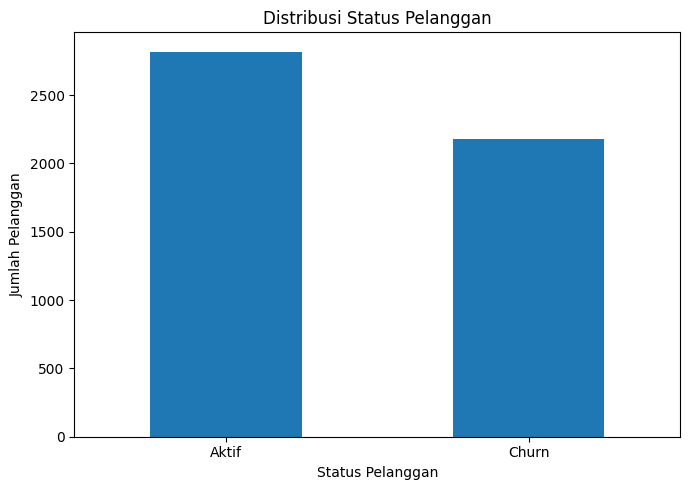

In [90]:
# Grafik distribusi status pelanggan
plt.figure(figsize=(7, 5))

distribusi_status.plot(
    kind="bar",
    rot=0
)

plt.title("Distribusi Status Pelanggan")
plt.xlabel("Status Pelanggan")
plt.ylabel("Jumlah Pelanggan")
plt.tight_layout()
plt.show()

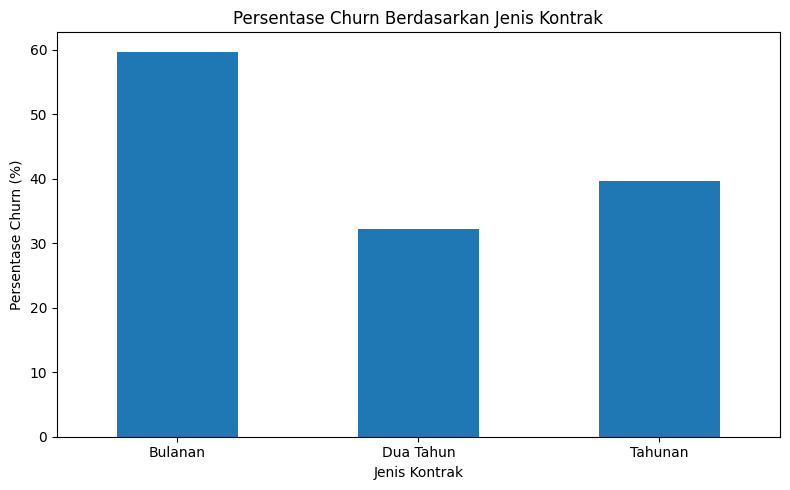

In [91]:
# Grafik persentase churn berdasarkan jenis kontrak
plt.figure(figsize=(8, 5))

persentase_churn_kontrak.plot(
    kind="bar",
    rot=0
)

plt.title("Persentase Churn Berdasarkan Jenis Kontrak")
plt.xlabel("Jenis Kontrak")
plt.ylabel("Persentase Churn (%)")
plt.tight_layout()
plt.show()

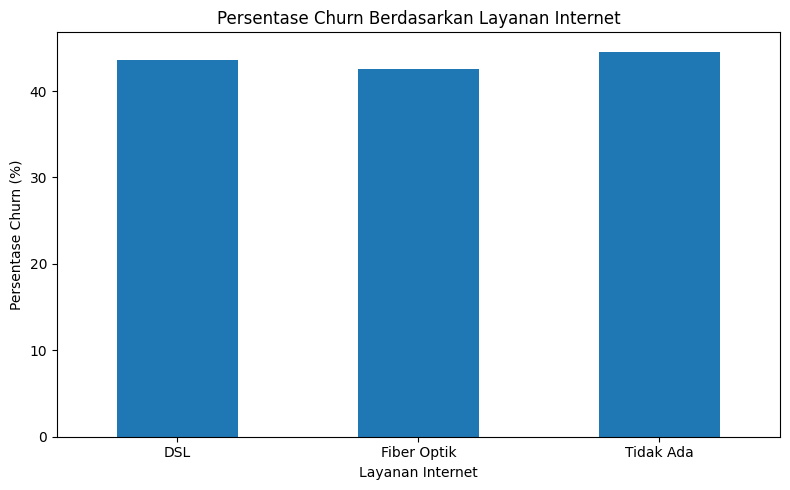

In [92]:
# Grafik persentase churn berdasarkan layanan internet
plt.figure(figsize=(8, 5))

persentase_churn_internet.plot(
    kind="bar",
    rot=0
)

plt.title("Persentase Churn Berdasarkan Layanan Internet")
plt.xlabel("Layanan Internet")
plt.ylabel("Persentase Churn (%)")
plt.tight_layout()
plt.show()

In [93]:
kontrak_tertinggi = persentase_churn_kontrak.idxmax()
nilai_kontrak = persentase_churn_kontrak.max()

internet_tertinggi = persentase_churn_internet.idxmax()
nilai_internet = persentase_churn_internet.max()

teknis_tertinggi = persentase_churn_teknis.idxmax()
nilai_teknis = persentase_churn_teknis.max()

print("TEMUAN ANALISIS")

print(
    f"1. Jenis kontrak dengan persentase churn tertinggi "
    f"adalah {kontrak_tertinggi} sebesar {nilai_kontrak}%."
)

print(
    f"2. Layanan internet dengan persentase churn tertinggi "
    f"adalah {internet_tertinggi} sebesar {nilai_internet}%."
)

print(
    f"3. Kelompok dukungan teknis dengan persentase churn tertinggi "
    f"adalah {teknis_tertinggi} sebesar {nilai_teknis}%."
)

TEMUAN ANALISIS
1. Jenis kontrak dengan persentase churn tertinggi adalah Bulanan sebesar 59.72%.
2. Layanan internet dengan persentase churn tertinggi adalah Tidak Ada sebesar 44.56%.
3. Kelompok dukungan teknis dengan persentase churn tertinggi adalah Tidak sebesar 44.35%.


In [94]:
# Mengambil data mentah dan menghapus duplikat berdasarkan customer_id
data_model = df_mentah.drop_duplicates(
    subset=["customer_id"]
).copy()

# Memisahkan fitur dan target
X = data_model.drop(
    columns=["customer_id", "status_pelanggan"]
)

y = data_model["status_pelanggan"]

# Menentukan kolom numerik dan kategorikal
fitur_num = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

fitur_kat = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Fitur numerik:", fitur_num)
print("Fitur kategorikal:", fitur_kat)
print("Target:", y.name)

Fitur numerik: ['lama_berlangganan_bulan', 'tagihan_bulanan_idr', 'total_tagihan_idr', 'jumlah_layanan_aktif', 'jumlah_komplain', 'hari_sejak_interaksi_terakhir']
Fitur kategorikal: ['jenis_kontrak', 'layanan_internet', 'dukungan_teknis', 'metode_pembayaran']
Target: status_pelanggan


In [95]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 4000
Jumlah data testing: 1000


In [96]:
# Pipeline untuk data numerik
pipeline_num = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline untuk data kategorikal
pipeline_kat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("numerik", pipeline_num, fitur_num),
    ("kategorikal", pipeline_kat, fitur_kat)
])

# Fit hanya pada data training
X_train_processed = preprocessor.fit_transform(X_train)

# Data testing hanya ditransformasi
X_test_processed = preprocessor.transform(X_test)

print("Persiapan data model berhasil!")
print("Ukuran X_train:", X_train_processed.shape)
print("Ukuran X_test:", X_test_processed.shape)

Persiapan data model berhasil!
Ukuran X_train: (4000, 27)
Ukuran X_test: (1000, 27)


In [97]:
import os

# Membuat folder output
os.makedirs("output", exist_ok=True)

# Menyimpan dataset bersih
df.to_csv(
    "output/data_bersih.csv",
    index=False
)

print("Dataset bersih berhasil disimpan!")

Dataset bersih berhasil disimpan!


In [98]:
# Membuat kamus data
kamus_data = pd.DataFrame({
    "kolom": df.columns,
    "tipe_data": df.dtypes.astype(str).values,
    "n_missing": df.isnull().sum().values,
    "n_unik": df.nunique().values
})

display(kamus_data)

# Menyimpan kamus data
kamus_data.to_csv(
    "output/kamus_data.csv",
    index=False
)

print("Kamus data berhasil disimpan!")

,kolom,tipe_data,n_missing,n_unik
0,customer_id,object,0,5000
1,lama_berlangganan_bulan,int64,0,72
2,jenis_kontrak,string,0,3
3,tagihan_bulanan_idr,float64,0,4822
4,total_tagihan_idr,float64,0,4673
5,layanan_internet,object,0,3
6,jumlah_layanan_aktif,int64,0,8
7,dukungan_teknis,object,0,2
8,jumlah_komplain,int64,0,16
9,hari_sejak_interaksi_terakhir,int64,0,366


Kamus data berhasil disimpan!


In [99]:
# Menyimpan laporan kualitas
laporan.to_csv(
    "laporan_kualitas.csv",
    index=True
)

print("Laporan kualitas berhasil disimpan!")

Laporan kualitas berhasil disimpan!
